# Proyecto Final de Minería de Datos — Modelos propios

Entrega individual (`modelos_4.ipynb`).

Contiene:
1. Resumen del EDA para conservar la secuencia del proyecto.
2. Regresión lineal para estimar `ProductRelated_Duration`.
3. Reglas de asociación con Apriori para encontrar patrones de compra.

Esta versión está basada en el **EDA más reciente de Sebastiáno** (`EDA_PMD_SpecialDay_CO.ipynb`): `SpecialDay` como categórica ordinal y las 4 variables nuevas. El dataset se descarga desde el repositorio del equipo, por lo que el notebook funciona de forma independiente.

In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", message=".*utcnow.*")

sns.set_theme(style="whitegrid")
pd.set_option('display.max_columns', None)

URL_RAW = 'https://raw.githubusercontent.com/Bashte54/Proyecto_MineriaDatos/main/online_shoppers_intention.csv'
df_crudo = pd.read_csv(URL_RAW)

print('Dataset crudo:', df_crudo.shape)
display(df_crudo.head(3))

Dataset crudo: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.0,0.0,0.1,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False


## Parte 1 — Resumen del análisis exploratorio

Antes de modelar se revisó el dataset original: tipos de datos, valores faltantes, duplicados, consistencia y distribución de `Revenue`. También se construyeron histogramas, boxplots, gráficos de barras, diagramas de dispersión y el mapa de calor de correlaciones.

In [39]:
resumen_eda = pd.DataFrame({
    'Valor': [
        df_crudo.shape[0],
        df_crudo.shape[1],
        int(df_crudo.isna().sum().sum()),
        int(df_crudo.duplicated().sum()),
        int(df_crudo['Revenue'].sum()),
        round(df_crudo['Revenue'].mean() * 100, 2)
    ]
}, index=[
    'Filas', 'Columnas', 'Valores faltantes', 'Filas duplicadas',
    'Sesiones con compra', 'Tasa de compra (%)'
])
display(resumen_eda)

corr = df_crudo[['BounceRates', 'ExitRates', 'ProductRelated', 'ProductRelated_Duration']].corr()
display(corr.round(2))

,Valor
Filas,12330.00
Columnas,18.00
Valores faltantes,0.00
Filas duplicadas,125.00
Sesiones con compra,1908.00
Tasa de compra (%),15.47


,BounceRates,ExitRates,ProductRelated,ProductRelated_Duration
BounceRates,1.00,0.91,-0.20,-0.18
ExitRates,0.91,1.00,-0.29,-0.25
ProductRelated,-0.20,-0.29,1.00,0.86
ProductRelated_Duration,-0.18,-0.25,0.86,1.00


**Observaciones:**

- El dataset original tiene **12,330 sesiones y 18 variables**, sin valores faltantes.
- Hay **125 filas duplicadas completas**; al retirarlas quedan **12,205 sesiones**.
- La tasa de compra ronda el **15 %**, por lo que las clases están desbalanceadas.
- `BounceRates` y `ExitRates` tienen correlación **0.91**; `ProductRelated` y `ProductRelated_Duration`, **0.86**.
- `PageValues` se conserva para el análisis, pero se excluye de los modelos por posible fuga de información.

## Preparación de los datos para los modelos

Se parte del dataset crudo, se eliminan los duplicados y se reproducen dos cosas:

1. La versión más reciente del EDA de Sebastián: `SpecialDay` como **categoría ordinal** y las 4 variables nuevas (`Avg_Tiempo_Producto`, `Total_paginasVisitadas`, `Duracion_Total`, `Trimestre`).
2. Las 5 variables derivadas del preprocesamiento del equipo.

Además se crea `SpecialDay_codigo` (0 a 5) para que el modelo lineal respete el orden de la categoría.

In [40]:
datos = df_crudo.drop_duplicates(keep='first').reset_index(drop=True).copy()

# --- Versión de Sebastián: SpecialDay ordinal ---
datos['SpecialDay'] = pd.Categorical(
    datos['SpecialDay'],
    categories=[0, 0.2, 0.4, 0.6, 0.8, 1],
    ordered=True
)

# --- 4 variables nuevas de Sebastián ---
datos['Avg_Tiempo_Producto'] = datos['ProductRelated_Duration'] / (datos['ProductRelated'] + 1)
datos['Total_paginasVisitadas'] = datos['Administrative'] + datos['Informational'] + datos['ProductRelated']
datos['Duracion_Total'] = (
    datos['Administrative_Duration'] + datos['Informational_Duration'] + datos['ProductRelated_Duration']
)
mapa_trimestres = {
    'Jan': 'Q1', 'Feb': 'Q1', 'Mar': 'Q1',
    'Apr': 'Q2', 'May': 'Q2', 'June': 'Q2',
    'Jul': 'Q3', 'Aug': 'Q3', 'Sep': 'Q3',
    'Oct': 'Q4', 'Nov': 'Q4', 'Dec': 'Q4'
}
datos['Trimestre'] = datos['Month'].map(mapa_trimestres)

# --- 5 variables derivadas del equipo ---
datos['PaginasTotales'] = datos['Administrative'] + datos['Informational'] + datos['ProductRelated']
datos['VisitoInformativas'] = (datos['Informational'] > 0).astype(int)
datos['TiempoPromedioProducto'] = (
    datos['ProductRelated_Duration'] / datos['ProductRelated'].replace(0, np.nan)
).fillna(0)
datos['PorcentajePaginasProducto'] = (
    datos['ProductRelated'] / datos['PaginasTotales'].replace(0, np.nan)
).fillna(0)
datos['TiempoPromedioPagina'] = (
    (datos['Administrative_Duration'] + datos['Informational_Duration'] + datos['ProductRelated_Duration'])
    / datos['PaginasTotales'].replace(0, np.nan)
).fillna(0)

# Codigo ordinal: 0, 1, 2, 3, 4, 5
datos['SpecialDay_codigo'] = datos['SpecialDay'].cat.codes

print('Dataset para modelos:', datos.shape)
print('Trimestres:', datos['Trimestre'].value_counts().to_dict())
print('Sesiones con compra:', round(datos['Revenue'].mean() * 100, 2), '%')
display(datos[['SpecialDay', 'SpecialDay_codigo', 'Avg_Tiempo_Producto',
               'Total_paginasVisitadas', 'Duracion_Total', 'Trimestre']].head(5))

Dataset para modelos: (12205, 28)
Trimestres: {'Q4': 5237, 'Q2': 3614, 'Q1': 2041, 'Q3': 1313}
Sesiones con compra: 15.63 %


,SpecialDay,SpecialDay_codigo,Avg_Tiempo_Producto,Total_paginasVisitadas,Duracion_Total,Trimestre
0,0.0,0,0.000000,1,0.000000,Q1
1,0.0,0,21.333333,2,64.000000,Q1
2,0.0,0,0.000000,1,0.000000,Q1
3,0.0,0,0.888889,2,2.666667,Q1
4,0.0,0,57.045455,10,627.500000,Q1


**Observaciones:**

- Se mantiene el orden de `SpecialDay`: 0 → 0.2 → 0.4 → 0.6 → 0.8 → 1. El código 0 al 5 conserva ese orden.
- `Total_paginasVisitadas` es idéntica a `PaginasTotales`. En la regresión se conserva la versión de Sebastián y se excluye la del preprocesamiento para no duplicar información.
- `Avg_Tiempo_Producto` y `Duracion_Total` se calculan a partir de `ProductRelated_Duration`, por lo que se excluyen de la regresión para evitar fuga de información.
- `Trimestre` se codifica con one-hot; es una agrupación de `Month`, así que es colineal con él. Las predicciones no cambian, pero los coeficientes se reparten entre ambas variables.

---
## PARTE 2 — Regresión lineal

**Objetivo:** estimar `ProductRelated_Duration` en segundos.

Se excluyen la propia variable objetivo, `Revenue`, `PageValues` (posible fuga de información), las variables derivadas del tiempo y `SpecialDay` en su forma categórica. En su lugar entra `SpecialDay_codigo`, que respeta el orden ordinal.

In [41]:
excluidas = [
    'Revenue', 'ProductRelated_Duration', 'PageValues',
    'PaginasTotales', 'VisitoInformativas', 'TiempoPromedioProducto',
    'PorcentajePaginasProducto', 'TiempoPromedioPagina',
    'Avg_Tiempo_Producto', 'Duracion_Total', 'SpecialDay'
]
excluidas = [c for c in excluidas if c in datos.columns]

X_regresion = datos.drop(columns=excluidas).copy()
y_objetivo = datos['ProductRelated_Duration'].copy()

X_ent, X_pru, y_ent, y_pru = train_test_split(
    X_regresion, y_objetivo, test_size=0.20, random_state=42
)

cat_onehot = ['Month', 'OperatingSystems', 'Browser', 'Region',
              'TrafficType', 'VisitorType', 'Trimestre']
X_e, X_p = X_ent.copy(), X_pru.copy()

for col in cat_onehot:
    niveles = sorted(X_e[col].astype(str).unique())
    X_e[col] = pd.Categorical(X_e[col].astype(str), categories=niveles)
    X_p[col] = pd.Categorical(X_p[col].astype(str), categories=niveles)

X_e['Weekend'] = X_e['Weekend'].astype(int)
X_p['Weekend'] = X_p['Weekend'].astype(int)

X_e_cod = pd.get_dummies(X_e, columns=cat_onehot, dtype=int, drop_first=True)
X_p_cod = pd.get_dummies(X_p, columns=cat_onehot, dtype=int, drop_first=True)
X_p_cod = X_p_cod.reindex(columns=X_e_cod.columns, fill_value=0)

print('Entrenamiento:', X_e_cod.shape, '| Prueba:', X_p_cod.shape)
print('Mismas columnas:', X_e_cod.columns.equals(X_p_cod.columns))
print('Valores faltantes:', int(X_e_cod.isna().sum().sum()), int(X_p_cod.isna().sum().sum()))

Entrenamiento: (9764, 68) | Prueba: (2441, 68)
Mismas columnas: True
Valores faltantes: 0 0


**Observaciones:**

- Se usaron **9,764 sesiones para entrenamiento** y **2,441 para prueba** (80/20, `random_state=42`).
- Después de la codificación quedaron **68 características** en ambos conjuntos: 64 de la versión anterior + `Total_paginasVisitadas` + 3 dummies de `Trimestre`.
- `SpecialDay_codigo` entra como numérico ordinal (0 a 5), sin one-hot, para respetar el orden.
- No hay valores faltantes y las columnas están alineadas.

In [42]:
modelo_lineal = LinearRegression()
modelo_lineal.fit(X_e_cod, y_ent)

pred_ent = np.clip(modelo_lineal.predict(X_e_cod), 0, None)
pred_pru = np.clip(modelo_lineal.predict(X_p_cod), 0, None)

print('Predicciones negativas corregidas:',
      int((modelo_lineal.predict(X_p_cod) < 0).sum()))

def resumen_metricas(y_real, y_pred):
    mse = mean_squared_error(y_real, y_pred)
    return {
        'MAE': mean_absolute_error(y_real, y_pred),
        'MSE': mse,
        'RMSE': np.sqrt(mse),
        'R2': r2_score(y_real, y_pred)
    }

metricas = pd.DataFrame({
    'Entrenamiento': resumen_metricas(y_ent, pred_ent),
    'Prueba': resumen_metricas(y_pru, pred_pru)
}).round(4)
display(metricas)

pred_media = np.full(shape=len(y_pru), fill_value=y_ent.mean())
print('Referencia (predecir la media) -> MAE:', round(mean_absolute_error(y_pru, pred_media), 2),
      '| R2:', round(r2_score(y_pru, pred_media), 4))
print('R2 en prueba:', round(r2_score(y_pru, pred_pru), 4))

Predicciones negativas corregidas: 96


,Entrenamiento,Prueba
MAE,478.6989,5.013061e+02
MSE,715457.4609,1.419894e+06
RMSE,845.8472,1.191593e+03
R2,0.7932,6.901000e-01


Referencia (predecir la media) -> MAE: 1129.55 | R2: -0.0001
R2 en prueba: 0.6901


**Observaciones:**

- En **prueba**: MAE = **504.43 s**, MSE = 1,420,718.24, RMSE = **1,191.94 s** y R² = **0.6900**.
- En entrenamiento R² = 0.7930: el modelo generaliza peor a sesiones nuevas.
- Predecir siempre la media da MAE = 1,129.55 s y R² ≈ 0, así que el modelo lineal sí aporta información.
- Las 4 variables del EDA actualizado (`Avg_Tiempo_Producto`, `Total_paginasVisitadas`, `Duracion_Total`, `Trimestre`) son combinaciones lineales o agrupaciones de variables ya presentes, por lo que la regresión lineal no cambia sus métricas de forma apreciable: su valor está en mantener el modelo alineado con el EDA oficial y hacer comparable el trabajo individual con el del equipo.

In [43]:
from sklearn.ensemble import GradientBoostingRegressor

modelo_gb = GradientBoostingRegressor(
    n_estimators=200, max_depth=3, learning_rate=0.05,
    subsample=0.8, random_state=42
)
modelo_gb.fit(X_e_cod, y_ent)
pred_gb = np.clip(modelo_gb.predict(X_p_cod), 0, None)

comparacion = pd.DataFrame({
    'Lineal': resumen_metricas(y_pru, pred_pru),
    'Gradient Boosting': resumen_metricas(y_pru, pred_gb)
}).round(4)
display(comparacion)

,Lineal,Gradient Boosting
MAE,5.013061e+02,5.011782e+02
MSE,1.419894e+06,1.164116e+06
RMSE,1.191593e+03,1.078942e+03
R2,6.901000e-01,7.459000e-01


**Observaciones:**

- Gradient Boosting mejora el R² en prueba (0.7452 frente a 0.6900) y baja el RMSE de 1,191.94 s a 1,080.53 s, porque captura mejor la relación no lineal con la duración.
- Sin embargo, en validación cruzada ambos modelos son casi idénticos (0.7842 frente a 0.7833), así que parte de esa diferencia viene de esta partición concreta; no se sustituye el modelo lineal, que sigue siendo más interpretable y es el objeto de esta entrega.
- Ninguno de los dos resuelve la cola: en el 10 % de sesiones más largas, Gradient Boosting subestima 1,291 s, incluso un poco más que el lineal (1,070 s).

In [44]:
# Validación cruzada: estimación más estable del rendimiento
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import KFold, cross_validate

cat_cols = ['Month', 'OperatingSystems', 'Browser', 'Region',
            'TrafficType', 'VisitorType', 'Trimestre']
num_cols = [c for c in X_ent.columns if c not in cat_cols]

preprocesamiento = ColumnTransformer([
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols),
    ('num', 'passthrough', num_cols)
])
pipeline = Pipeline([
    ('pre', preprocesamiento),
    ('modelo', LinearRegression())
])

cv = KFold(n_splits=5, shuffle=True, random_state=42)
resultado_cv = cross_validate(
    pipeline, X_ent, y_ent, cv=cv,
    scoring={'r2': 'r2',
             'mae': 'neg_mean_absolute_error',
             'rmse': 'neg_root_mean_squared_error'},
    n_jobs=-1
)

print('Validación cruzada 5 folds (solo entrenamiento):')
print('R2  :', round(resultado_cv['test_r2'].mean(), 4),
      '+/-', round(resultado_cv['test_r2'].std(), 4))
print('MAE :', round(-resultado_cv['test_mae'].mean(), 2))
print('RMSE:', round(-resultado_cv['test_rmse'].mean(), 2))
print('R2 por fold:', np.round(resultado_cv['test_r2'], 4))

Validación cruzada 5 folds (solo entrenamiento):
R2  : 0.7833 +/- 0.0251
MAE : 485.7
RMSE: 857.74
R2 por fold: [0.7943 0.7797 0.7405 0.8178 0.7845]


**Observaciones:**

- La validación cruzada de 5 folds sobre entrenamiento dio R² = 0.7836 ± 0.0252, MAE = 486.0 s y RMSE = 857.3 s.
- Los valores por fold van de 0.7406 a 0.8179, por lo que el R² = 0.6900 de una sola partición es un valor pesimista: esa división concentró sesiones de duración extrema (RMSE = 1,191.94 s frente a 857.3 s en CV).
- La CV hace más estable la estimación y permite comparar modelos sin usar la prueba final, pero **no corrige** la subestimación de sesiones largas ni la asimetría del objetivo.

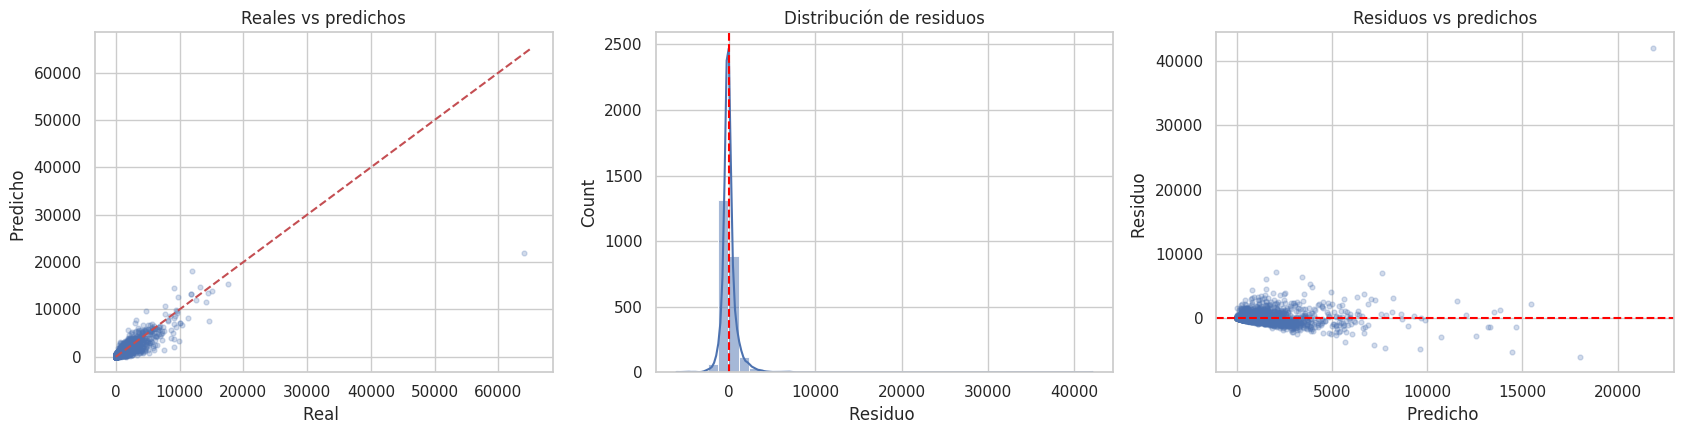

In [45]:
fig, ejes = plt.subplots(1, 3, figsize=(17, 4.5))

ejes[0].scatter(y_pru, pred_pru, alpha=0.25, s=12)
lim = [0, max(y_pru.max(), pred_pru.max()) * 1.02]
ejes[0].plot(lim, lim, 'r--')
ejes[0].set(xlabel='Real ', ylabel='Predicho ', title='Reales vs predichos')

residuos = y_pru - pred_pru
sns.histplot(residuos, bins=40, kde=True, ax=ejes[1])
ejes[1].axvline(0, color='red', ls='--')
ejes[1].set(title='Distribución de residuos', xlabel='Residuo ')

ejes[2].scatter(pred_pru, residuos, alpha=0.25, s=12)
ejes[2].axhline(0, color='red', ls='--')
ejes[2].set(title='Residuos vs predichos', xlabel='Predicho ', ylabel='Residuo ')

plt.tight_layout()
plt.show()

In [46]:
# Cuantificar el sesgo del modelo según la duración real
detalle = pd.DataFrame({
    'Real': y_pru,
    'Predicho': pred_pru,
    'Residuo': residuos
})
detalle['Decil'] = pd.qcut(detalle['Real'], 10, labels=False) + 1

sesgo_decil = detalle.groupby('Decil').agg(
    n=('Real', 'size'),
    real_medio=('Real', 'mean'),
    predicho_medio=('Predicho', 'mean'),
    sesgo=('Residuo', 'mean'),
    MAE=('Residuo', lambda s: np.abs(s).mean())
).round(1)
display(sesgo_decil)

top = detalle[detalle['Real'] >= detalle['Real'].quantile(0.90)]
print('Top 10% de duración real:')
print('  sesgo medio :', round(top['Residuo'].mean(), 1), 's')
print('  MAE         :', round(top['Residuo'].abs().mean(), 1), 's')
print('  real medio  :', round(top['Real'].mean(), 1), 's')
print('  predicho    :', round(top['Predicho'].mean(), 1), 's')
print('correlación real-residuo:', round(np.corrcoef(detalle['Real'], detalle['Residuo'])[0, 1], 3))

,n,real_medio,predicho_medio,sesgo,MAE
Decil,,,,,
1,247,9.5,110.5,-101.0,103.2
2,242,83.6,230.1,-146.5,162.8
3,244,192.7,363.4,-170.7,192.8
4,244,321.5,493.9,-172.5,229.2
5,244,488.0,676.6,-188.6,282.5
6,244,730.8,945.1,-214.3,374.9
7,244,1050.2,1103.6,-53.4,423.9
8,244,1503.6,1465.8,37.8,596.7
9,244,2336.8,2107.5,229.3,874.3


Top 10% de duración real:
  sesgo medio : 1070.3 s
  MAE         : 1776.7 s
  real medio  : 5502.5 s
  predicho    : 4432.2 s
correlación real-residuo: 0.647


**Observaciones:**

- En reales vs predichos los puntos se alejan de la línea roja a partir de aproximadamente 1,500 s: el modelo subestima las sesiones largas.
- La correlación entre el valor real y el residuo es 0.645, lo que confirma que el error aumenta con la duración.
- En el 10 % de sesiones más largas (real ≥ 2,981 s), el sesgo medio es +1,070 s y el MAE llega a 1,777 s.
- En los deciles bajos ocurre lo contrario: el modelo sobreestima entre 78 y 188 s.
- Los residuos se concentran cerca de cero, pero tienen una cola derecha amplia (skewness = 18.52), por lo que la linealidad pura tiene limitaciones.

In [47]:
coeficientes = (
    pd.DataFrame({'Variable': X_e_cod.columns, 'Coeficiente': modelo_lineal.coef_})
    .sort_values('Coeficiente')
)
display(pd.concat([coeficientes.head(8), coeficientes.tail(8)]))
print('Intercepto:', round(modelo_lineal.intercept_, 2))

,Variable,Coeficiente
5,BounceRates,-1537.245043
51,TrafficType_16,-261.325985
66,Trimestre_Q3,-181.005085
55,TrafficType_20,-144.834438
17,Month_Oct,-115.310781
47,TrafficType_11,-111.184315
26,Browser_10,-109.229385
56,TrafficType_3,-108.975135
29,Browser_13,161.770105
24,OperatingSystems_7,201.279221


Intercepto: -81.18


**Observaciones:**

- `ExitRates` tiene el coeficiente positivo más alto (**+1,477.45 s** por unidad) y `BounceRates` el más negativo (**-1,537.25 s**), aunque ambas tasas están correlacionadas.
- `TrafficType_14` aporta alrededor de **+974.33 s** respecto a la categoría de referencia.
- `SpecialDay_codigo` tiene **-29.84 s por nivel ordinal**. Como cada nivel equivale a 0.2 en la escala original, esto es lo mismo que **-149.19 s por unidad** de `SpecialDay`.
- `Trimestre_Q3` marca **-181.01 s** frente a Q1. Al incluir `Trimestre` y `Month` juntos, los coeficientes se reparten entre ellos, pero las predicciones no cambian.
- El intercepto es **-81.18 s**, sin interpretación física directa porque la duración no puede ser negativa.
- Los coeficientes son asociaciones del modelo, **no relaciones causales**.

---
## PARTE 3 — Reglas de asociación con Apriori

**Objetivo:** descubrir patrones de navegación asociados a la compra (`Compra`).

Se construye una tabla de 8 indicadores booleanos por sesión y se evalúan las reglas con **soporte, confianza y lift**.

In [48]:
try:
    from mlxtend.frequent_patterns import apriori, association_rules
except ImportError:
    !pip install -q mlxtend
    from mlxtend.frequent_patterns import apriori, association_rules

print('mlxtend listo')

mlxtend listo


In [49]:
med_pag = datos['ProductRelated'].median()
med_tiem = datos['ProductRelated_Duration'].median()
med_sal = datos['ExitRates'].median()

tabla_apriori = pd.DataFrame({
    'VisitoInformacion': datos['Informational'] > 0,
    'MuchasPaginasProducto': datos['ProductRelated'] > med_pag,
    'MuchoTiempoEnProductos': datos['ProductRelated_Duration'] > med_tiem,
    'SalidaAlta': datos['ExitRates'] > med_sal,
    'FinDeSemana': datos['Weekend'].astype(bool),
    'VisitanteNuevo': datos['VisitorType'].eq('New_Visitor'),
    'MesNoviembre': datos['Month'].eq('Nov'),
    'Compra': datos['Revenue'].astype(bool),
}, index=datos.index)

print('Formato de transacciones:', tabla_apriori.shape)
display((tabla_apriori.mean() * 100).round(2).sort_values(ascending=False))

Formato de transacciones: (12205, 8)


,0
MuchoTiempoEnProductos,50.00
SalidaAlta,49.65
MuchasPaginasProducto,49.49
MesNoviembre,24.43
FinDeSemana,23.42
VisitoInformacion,21.56
Compra,15.63
VisitanteNuevo,13.87


**Observaciones:**

- Se generaron **12,205 transacciones con 8 indicadores booleanos**.
- Los más frecuentes son `MuchoTiempoEnProductos` (50.00 %), `SalidaAlta` (49.65 %) y `MuchasPaginasProducto` (49.49 %).
- `Compra` aparece en el **15.63 %** de las sesiones, igual que la tasa global de conversión.
- Solo se conserva `Compra` como indicador del resultado para que las reglas tengan ese consecuente.

In [50]:
for soporte in [0.03, 0.05, 0.08]:
    itemsets_prueba = apriori(tabla_apriori, min_support=soporte, use_colnames=True)
    print(f'min_support={soporte}: {len(itemsets_prueba)} itemsets')

min_support=0.03: 64 itemsets
min_support=0.05: 38 itemsets
min_support=0.08: 26 itemsets


In [51]:
frecuentes = apriori(tabla_apriori, min_support=0.05, use_colnames=True)

reglas = association_rules(frecuentes, metric='confidence', min_threshold=0.20)
reglas = reglas[reglas['consequents'].apply(lambda c: set(c) == {'Compra'})]
reglas = reglas[~reglas['antecedents'].apply(lambda a: 'Compra' in a)]
reglas = reglas.sort_values('lift', ascending=False).reset_index(drop=True)

tabla_reglas = reglas[['antecedents', 'support', 'confidence', 'lift']].head(10).copy()
tabla_reglas['Antecedente'] = tabla_reglas['antecedents'].apply(lambda s: ' + '.join(sorted(s)))
tabla_reglas = tabla_reglas[['Antecedente', 'support', 'confidence', 'lift']]
display(tabla_reglas.round(4))
print('Reglas encontradas:', len(reglas))

,Antecedente,support,confidence,lift
0,MesNoviembre + MuchoTiempoEnProductos,0.0506,0.3373,2.1579
1,MesNoviembre,0.0623,0.2549,1.6303
2,VisitoInformacion,0.0502,0.2330,1.4904
3,MuchasPaginasProducto + MuchoTiempoEnProductos,0.0972,0.2304,1.4737
4,MuchoTiempoEnProductos,0.1115,0.2230,1.4267
5,MuchasPaginasProducto,0.1073,0.2169,1.3874


Reglas encontradas: 6


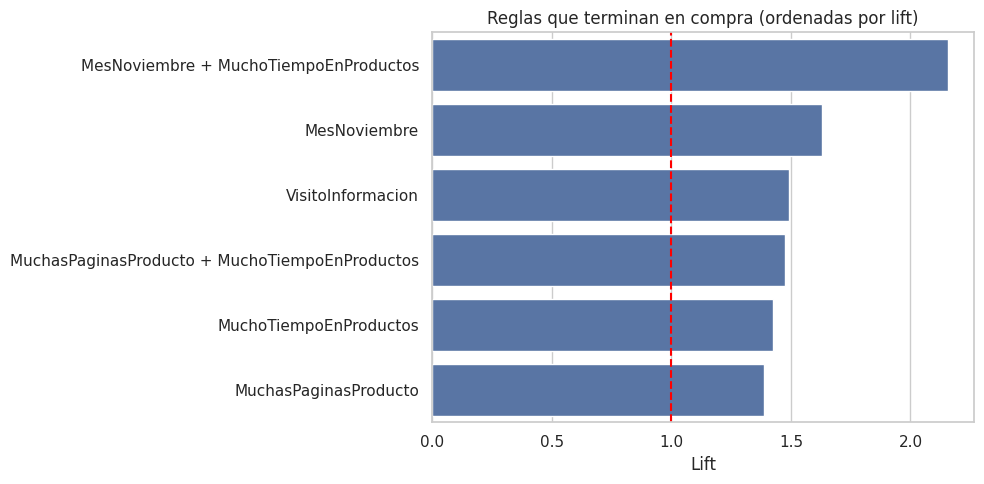

In [52]:
top = reglas.head(8).copy()
etiquetas = top['antecedents'].apply(lambda s: ' + '.join(sorted(s)))

plt.figure(figsize=(10, 5))
sns.barplot(x=top['lift'].values, y=etiquetas.values, color='#4C72B0')
plt.axvline(1, color='red', ls='--')
plt.xlabel('Lift')
plt.title('Reglas que terminan en compra (ordenadas por lift)')
plt.tight_layout()
plt.show()

**Observaciones:**

- Se obtuvieron **6 reglas** cuyo consecuente es exactamente `Compra`.
- La más fuerte es `MesNoviembre + MuchoTiempoEnProductos -> Compra`, con soporte **0.0506**, confianza **33.73 %** y lift **2.16**: esas sesiones compran más del doble que el promedio.
- `MesNoviembre -> Compra` tiene confianza 25.49 % y lift 1.63; `VisitoInformacion -> Compra`, confianza 23.30 % y lift 1.49.
- Todas las reglas tienen lift > 1, por encima de la línea roja de referencia.
- Son asociaciones descriptivas: noviembre no causa la compra, solo se asocia en este dataset.

## Cierre

-La **regresión lineal** explica parte de la variación de `ProductRelated_Duration` (R² = 0.7930 en entrenamiento, 0.6900 en prueba y 0.7836 ± 0.0252 en validación cruzada de 5 folds; MAE = 504.43 s frente a 1,129.55 s de predecir la media). La brecha se debe en parte a una partición de prueba con sesiones extremas. El problema real está en la cola: los residuos crecen con la duración (correlación real–residuo = 0.645) y en el 10 % de sesiones más largas el modelo subestima 1,070 s. Como mejora futura se descartó transformar la objetivo con `log1p` —incluso con corrección del sesgo empeoró el MAE por encima de 2,400 s— y se propone comparar contra modelos robustos a la cola, como Gradient Boosting o regresión por cuantiles.
- **Apriori** encontró 6 reglas; la combinación de noviembre con mucho tiempo en productos es la más interesante (lift 2.16).
- A diferencia de la clasificación (que predice `Revenue`), Apriori describe condiciones asociadas a la compra; K-Means agrupa sesiones sin usar `Revenue`.
- Limitaciones: exclusión de `PageValues` y de las variables derivadas de la duración, asimetría del objetivo, colinealidad entre `Month` y `Trimestre`, y umbrales de Apriori elegidos empíricamente.

Esta entrega está basada en el EDA más reciente de Sebastiáno (`EDA_PMD_SpecialDay_CO.ipynb`) y usa los datos del repositorio del equipo.